In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

from pprint import pprint
from sklearn.model_selection import cross_validate, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

RANDOM_STATE = 42
CV = 5

In [2]:
# BỘ DỮ LIỆU THỨ NHẤT  569 MẪU

from sklearn.datasets import load_breast_cancer
data = load_breast_cancer()   # mau: 569;   features: 30;    label: 2
x, y = data.data, data.target

In [3]:
print(x.shape)
print(y.shape)

(569, 30)
(569,)


In [4]:
def make_xgb_model(x, y, **params):
    """Tạo một bộ phân loại XGBoost cho các mục tiêu nhị phân hoặc đa lớp."""
    n_classes = len(np.unique(y))

    common = {
        "n_jobs": -1,
        "random_state": RANDOM_STATE,
        "tree_method": "hist",
    }
    common.update(params)

    if n_classes == 2:
        common.setdefault("objective", "binary:logistic")
        # num_class không cần thiết cho phân loại nhị phân.
    else:
        common.setdefault("objective", "multi:softprob")
        common.setdefault("num_class", n_classes)

    return XGBClassifier(**common)

In [5]:
model = make_xgb_model(x, y)
print("bo tham so mac dinh cua mo hinh: ")
pprint(model.get_params())

bo tham so mac dinh cua mo hinh: 
{'base_score': None,
 'booster': None,
 'callbacks': None,
 'colsample_bylevel': None,
 'colsample_bynode': None,
 'colsample_bytree': None,
 'device': None,
 'early_stopping_rounds': None,
 'enable_categorical': True,
 'eval_metric': None,
 'feature_types': None,
 'feature_weights': None,
 'gamma': None,
 'grow_policy': None,
 'importance_type': None,
 'interaction_constraints': None,
 'learning_rate': None,
 'max_bin': None,
 'max_cat_threshold': None,
 'max_cat_to_onehot': None,
 'max_delta_step': None,
 'max_depth': None,
 'max_leaves': None,
 'min_child_weight': None,
 'missing': nan,
 'monotone_constraints': None,
 'multi_strategy': None,
 'n_estimators': None,
 'n_jobs': -1,
 'num_parallel_tree': None,
 'objective': 'binary:logistic',
 'random_state': 42,
 'reg_alpha': None,
 'reg_lambda': None,
 'sampling_method': None,
 'scale_pos_weight': None,
 'subsample': None,
 'tree_method': 'hist',
 'validate_parameters': None,
 'verbosity': None}


In [6]:
def XGB(x, y):
    start = time.time()

    model = make_xgb_model(x, y)

    scores = cross_validate(
        model,
        x,
        y,
        cv=CV,
        scoring={
            "loss": "neg_log_loss",
            "acc": "accuracy"
        },
        n_jobs=-1
    )

    loss = -scores["test_loss"].mean()
    acc = scores["test_acc"].mean()
    exec_time = time.time() - start

    print("Loss:", loss)
    print("Accuracy:", acc)
    print("Thoi gian thuc thi:", exec_time)
    return loss, acc, exec_time

In [7]:
def Grid_Search_XGB(x, y):
    start = time.time()

    model = make_xgb_model(x, y)

    params = {
        "n_estimators": [100, 200, 300],
        "max_depth": [3, 6, 10],
        "learning_rate": [0.03, 0.1, 0.2],
        "subsample": [0.7, 0.85, 1.0]
    }

    model_grid = GridSearchCV(
        estimator=model,
        param_grid=params,
        cv=CV,
        scoring={
            "loss": "neg_log_loss",
            "acc": "accuracy"
        },
        refit="loss",
        n_jobs=-1
    )

    model_grid.fit(x, y)

    loss = -model_grid.best_score_
    acc = model_grid.cv_results_["mean_test_acc"][model_grid.best_index_]
    exec_time = time.time() - start

    print("Bo sieu tham so tot nhat Grid Search:", model_grid.best_params_)
    print("Loss:", loss)
    print("Accuracy:", acc)
    print("Thoi gian thuc thi:", exec_time)
    return loss, acc, exec_time

In [8]:
def Random_search_XGB(x, y, n_iter=100):
    start = time.time()

    model = make_xgb_model(x, y)

    params = {
        "n_estimators": range(50, 501, 10),
        "max_depth": range(3, 16),
        "learning_rate": np.linspace(0.01, 0.30, 30),
        "subsample": np.linspace(0.50, 1.00, 11)
    }

    search = RandomizedSearchCV(
        model,
        param_distributions=params,
        n_iter=n_iter,
        cv=CV,
        scoring={
            "loss": "neg_log_loss",
            "acc": "accuracy"
        },
        refit="loss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    search.fit(x, y)

    loss = -search.best_score_
    acc = search.cv_results_["mean_test_acc"][search.best_index_]
    exec_time = time.time() - start

    print("Best params Random Search:", search.best_params_)
    print("Loss:", loss)
    print("Accuracy:", acc)
    print("Thoi gian thuc thi:", exec_time)
    return loss, acc, exec_time

In [9]:
def PSO_XGB(x, y, n_particles=30, n_iter=20, seed=RANDOM_STATE):
    start = time.time()
    rng = np.random.default_rng(seed)

    def decode(params):
        n_estimators = int(np.clip(round(params[0]), 50, 500))
        max_depth = int(np.clip(round(params[1]), 3, 15))
        learning_rate = float(np.clip(params[2], 0.01, 0.30))
        subsample = float(np.clip(params[3], 0.50, 1.00))
        return {
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "learning_rate": learning_rate,
            "subsample": subsample
        }

    def fitness(params):
        model = make_xgb_model(x, y, **decode(params))
        return -cross_val_score(
            model, x, y, cv=CV, scoring="neg_log_loss", n_jobs=-1
        ).mean()

    dim = 4
    bounds = [
        (50, 500),
        (3, 15),
        (0.01, 0.30),
        (0.50, 1.00)
    ]
    lo = np.array([b[0] for b in bounds], dtype=float)
    hi = np.array([b[1] for b in bounds], dtype=float)

    positions = rng.uniform(lo, hi, (n_particles, dim))
    velocities = np.zeros((n_particles, dim))

    pbest = positions.copy()
    pbest_scores = np.array([fitness(p) for p in pbest])

    best_idx = np.argmin(pbest_scores)
    gbest = pbest[best_idx].copy()
    gbest_score = pbest_scores[best_idx]
    gbest_score_history = [gbest_score]

    w, c1, c2 = 0.7, 1.5, 1.5

    for t in range(n_iter):
        r1 = rng.random((n_particles, dim))
        r2 = rng.random((n_particles, dim))

        velocities = (
            w * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )
        positions += velocities

        for d, (bl, bh) in enumerate(bounds):
            positions[:, d] = np.clip(positions[:, d], bl, bh)

        scores = np.array([fitness(p) for p in positions])
        improved = scores < pbest_scores
        pbest[improved] = positions[improved]
        pbest_scores[improved] = scores[improved]

        best_idx = np.argmin(pbest_scores)
        if pbest_scores[best_idx] < gbest_score:
            gbest_score = pbest_scores[best_idx]
            gbest = pbest[best_idx].copy()

        gbest_score_history.append(gbest_score)
        print(f"Vong lap: {t + 1} | gbest_score: {gbest_score:.6f}")

    best_model = make_xgb_model(x, y, **decode(gbest))
    acc = cross_val_score(
        best_model, x, y, cv=CV, scoring="accuracy", n_jobs=-1
    ).mean()

    exec_time = time.time() - start
    print("Best params PSO-XGBoost:", decode(gbest))
    print("g_best_score:", gbest_score)
    print("Accuracy:", acc)
    print("Thoi gian thuc thi:", exec_time)

    return gbest_score, acc, exec_time, gbest_score_history

In [10]:
def AIW_PSO_XGB(
    x,
    y,
    n_particles=30,
    n_iter=20,
    w_min=0.4,
    w_max=0.9,
    c1_start=2.5,
    c1_end=0.5,
    c2_start=0.5,
    c2_end=2.5,
    stagnation_limit=3,
    reinit_ratio=0.2,
    seed=RANDOM_STATE
):
    """AAIW + TVAC + tái khởi tạo một phần dựa trên sự đình trệ cho XGBoost."""

    rng = np.random.default_rng(seed)
    start = time.time()

    def decode(params):
        n_estimators = int(np.clip(round(params[0]), 50, 500))
        max_depth = int(np.clip(round(params[1]), 3, 15))
        learning_rate = float(np.clip(params[2], 0.01, 0.30))
        subsample = float(np.clip(params[3], 0.50, 1.00))
        return {
            "n_estimators": n_estimators,
            "max_depth": max_depth,
            "learning_rate": learning_rate,
            "subsample": subsample
        }

    def fitness(params):
        model = make_xgb_model(x, y, **decode(params))
        return -cross_val_score(
            model, x, y, cv=CV, scoring="neg_log_loss", n_jobs=-1
        ).mean()

    def evaluate_accuracy(params):
        model = make_xgb_model(x, y, **decode(params))
        return cross_val_score(
            model, x, y, cv=CV, scoring="accuracy", n_jobs=-1
        ).mean()

    dim = 4
    bounds = [
        (50, 500),
        (3, 15),
        (0.01, 0.30),
        (0.50, 1.00)
    ]
    lo = np.array([b[0] for b in bounds], dtype=float)
    hi = np.array([b[1] for b in bounds], dtype=float)

    positions = rng.uniform(lo, hi, (n_particles, dim))
    velocities = np.zeros((n_particles, dim))

    pbest = positions.copy()
    pbest_scores = np.array([fitness(p) for p in pbest])

    best_idx = np.argmin(pbest_scores)
    gbest = pbest[best_idx].copy()
    gbest_score = pbest_scores[best_idx]

    gbest_score_history = [gbest_score]
    w_history = []
    stagnation_counter = 0
    EPS = 1e-10

    for t in range(n_iter):
        # TVAC: thành phần nhận thức giảm; thành phần xã hội tăng.
        c1 = c1_start - (c1_start - c1_end) * (t / n_iter)
        c2 = c2_start + (c2_end - c2_start) * (t / n_iter)

        # AIW: trọng số quán tính đặc thù cho từng hạt dựa trên giá trị độ thích nghi pbest hiện tại.
        f_min = pbest_scores.min()
        f_avg = pbest_scores.mean()

        if f_avg - f_min > EPS:
            w_vec = w_min + (w_max - w_min) * (
                (pbest_scores - f_min) / (f_avg - f_min)
            )
            w_vec = np.clip(w_vec, w_min, w_max)
        else:
            w_vec = np.full(n_particles, w_max)

        w_history.append(w_vec.mean())
        w_col = w_vec[:, None]

        r1 = rng.random((n_particles, dim))
        r2 = rng.random((n_particles, dim))

        velocities = (
            w_col * velocities
            + c1 * r1 * (pbest - positions)
            + c2 * r2 * (gbest - positions)
        )
        positions += velocities

        for d, (bl, bh) in enumerate(bounds):
            positions[:, d] = np.clip(positions[:, d], bl, bh)

        scores = np.array([fitness(p) for p in positions])
        improved = scores < pbest_scores
        pbest[improved] = positions[improved]
        pbest_scores[improved] = scores[improved]

        new_gbest_score = pbest_scores.min()
        if gbest_score - new_gbest_score > EPS:
            gbest_score = new_gbest_score
            gbest = pbest[np.argmin(pbest_scores)].copy()
            stagnation_counter = 0
        else:
            stagnation_counter += 1

        reinit_triggered = False
        if stagnation_counter >= stagnation_limit:
            n_reinit = max(1, int(reinit_ratio * n_particles))
            worst_idx = np.argsort(pbest_scores)[-n_reinit:]

            positions[worst_idx] = rng.uniform(
                lo, hi, (n_reinit, dim)
            )
            velocities[worst_idx] = 0

            #Đồng thời khởi tạo lại pbest để các hạt được khởi động lại
            #có thể tìm kiếm xung quanh vị trí mới của chúng, thay vì giữ lại
            #các giá trị pbest cũ.

            pbest[worst_idx] = positions[worst_idx]
            pbest_scores[worst_idx] = np.array(
                [fitness(p) for p in pbest[worst_idx]]
            )

            stagnation_counter = 0
            reinit_triggered = True

            # Kiểm tra lại gbest sau khi tái khởi tạo một phần.
            best_idx = np.argmin(pbest_scores)
            if pbest_scores[best_idx] < gbest_score:
                gbest_score = pbest_scores[best_idx]
                gbest = pbest[best_idx].copy()

        gbest_score_history.append(gbest_score)

        print(
            f"Vong lap: {t + 1} | gbest_score: {gbest_score:.6f} "
            f"| w_avg: {w_vec.mean():.3f} "
            f"c1: {c1:.2f} c2: {c2:.2f} "
            f"| mean_n_estimators: {positions[:, 0].mean():.1f} "
            f"mean_max_depth: {positions[:, 1].mean():.1f} "
            f"| reinit_triggered: {reinit_triggered}"
        )

    exec_time = time.time() - start
    gbest_acc = evaluate_accuracy(gbest)

    print("Best params AIW-PSO-XGBoost:", decode(gbest))
    print("g_best_score:", gbest_score)
    print("Accuracy:", gbest_acc)
    print("Thoi gian thuc thi:", exec_time)

    return (
        gbest_score,
        gbest_acc,
        exec_time,
        gbest_score_history,
        w_history
    )

In [ ]:
XGB(x, y)

Loss: 0.08479626236634394
Accuracy: 0.9736376339077782
Thoi gian thuc thi: 3.298192262649536


(np.float64(0.08479626236634394),
 np.float64(0.9736376339077782),
 3.298192262649536)

In [ ]:
Grid_Search_XGB(x, y)

Bo sieu tham so tot nhat Grid Search: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.7}
Loss: 0.081739310984807
Accuracy: 0.9771464058376027
Thoi gian thuc thi: 28.39861011505127


(np.float64(0.081739310984807),
 np.float64(0.9771464058376027),
 28.39861011505127)

In [ ]:
Random_search_XGB(x, y)

Best params Random Search: {'subsample': np.float64(0.6), 'n_estimators': 390, 'max_depth': 13, 'learning_rate': np.float64(0.23999999999999996)}
Loss: 0.07892753531921048
Accuracy: 0.9753764943331781
Thoi gian thuc thi: 33.53359913825989


(np.float64(0.07892753531921048),
 np.float64(0.9753764943331781),
 33.53359913825989)

In [ ]:
PSO_XGB(x, y)

Vong lap: 1 | gbest_score: 0.081171
Vong lap: 2 | gbest_score: 0.079579
Vong lap: 3 | gbest_score: 0.079477
Vong lap: 4 | gbest_score: 0.079477
Vong lap: 5 | gbest_score: 0.079477
Vong lap: 6 | gbest_score: 0.079477
Vong lap: 7 | gbest_score: 0.078037
Vong lap: 8 | gbest_score: 0.076754
Vong lap: 9 | gbest_score: 0.076754
Vong lap: 10 | gbest_score: 0.076754
Vong lap: 11 | gbest_score: 0.075080
Vong lap: 12 | gbest_score: 0.075080
Vong lap: 13 | gbest_score: 0.075080
Vong lap: 14 | gbest_score: 0.075080
Vong lap: 15 | gbest_score: 0.075080
Vong lap: 16 | gbest_score: 0.075080
Vong lap: 17 | gbest_score: 0.075080
Vong lap: 18 | gbest_score: 0.075080
Vong lap: 19 | gbest_score: 0.075080
Vong lap: 20 | gbest_score: 0.075080
Best params PSO-XGBoost: {'n_estimators': 467, 'max_depth': 11, 'learning_rate': 0.16595438569777782, 'subsample': 0.5347108252072893}
g_best_score: 0.07508018663808776
Accuracy: 0.9753920198726906
Thoi gian thuc thi: 208.981458902359


(np.float64(0.07508018663808776),
 np.float64(0.9753920198726906),
 208.981458902359,
 [np.float64(0.0823774434499067),
  np.float64(0.08117120370122605),
  np.float64(0.07957919966420618),
  np.float64(0.07947664000202317),
  np.float64(0.07947664000202317),
  np.float64(0.07947664000202317),
  np.float64(0.07947664000202317),
  np.float64(0.07803691896965123),
  np.float64(0.07675422559956976),
  np.float64(0.07675422559956976),
  np.float64(0.07675422559956976),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776),
  np.float64(0.07508018663808776)])

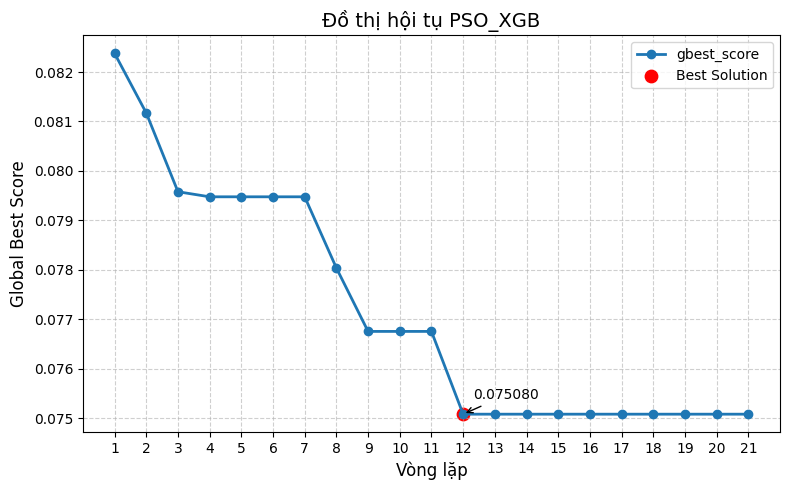

In [ ]:
import matplotlib.pyplot as plt

# Giá trị gbest_score theo từng vòng lặp
gbest_scores = [
  0.0823774434499067,
  0.08117120370122605,
  0.07957919966420618,
  0.07947664000202317,
  0.07947664000202317,
  0.07947664000202317,
  0.07947664000202317,
  0.07803691896965123,
  0.07675422559956976,
  0.07675422559956976,
  0.07675422559956976,
  0.07508018663808776,
  0.07508018663808776,
  0.07508018663808776,
  0.07508018663808776,
  0.07508018663808776,
  0.07508018663808776,
  0.07508018663808776,
  0.07508018663808776,
  0.07508018663808776,
  0.07508018663808776
]

# Tạo danh sách số vòng lặp
iterations = range(1, len(gbest_scores) + 1)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))
plt.plot(
    iterations,
    gbest_scores,
    marker='o',
    linewidth=2,
    markersize=6,
    label='gbest_score'
)

# Đánh dấu điểm tốt nhất
best_iter = gbest_scores.index(min(gbest_scores)) + 1
best_score = min(gbest_scores)

plt.scatter(best_iter, best_score, s=80, color='red', label='Best Solution')
plt.annotate(
    f'{best_score:.6f}',
    xy=(best_iter, best_score),
    xytext=(best_iter + 0.3, best_score + 0.0003),
    arrowprops=dict(arrowstyle='->')
)

# Thiết lập đồ thị
plt.title("Đồ thị hội tụ PSO_XGB", fontsize=14)
plt.xlabel("Vòng lặp", fontsize=12)
plt.ylabel("Global Best Score", fontsize=12)
plt.xticks(iterations)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
AIW_PSO_XGB(x, y)

Vong lap: 1 | gbest_score: 0.079395 | w_avg: 0.753 c1: 2.50 c2: 0.50 | mean_n_estimators: 305.9 mean_max_depth: 9.9 | reinit_triggered: False
Vong lap: 2 | gbest_score: 0.079395 | w_avg: 0.799 c1: 2.40 c2: 0.60 | mean_n_estimators: 289.6 mean_max_depth: 11.5 | reinit_triggered: False
Vong lap: 3 | gbest_score: 0.079395 | w_avg: 0.793 c1: 2.30 c2: 0.70 | mean_n_estimators: 243.3 mean_max_depth: 12.3 | reinit_triggered: False
Vong lap: 4 | gbest_score: 0.079395 | w_avg: 0.786 c1: 2.20 c2: 0.80 | mean_n_estimators: 227.3 mean_max_depth: 11.9 | reinit_triggered: True
Vong lap: 5 | gbest_score: 0.079395 | w_avg: 0.761 c1: 2.10 c2: 0.90 | mean_n_estimators: 229.0 mean_max_depth: 12.5 | reinit_triggered: False
Vong lap: 6 | gbest_score: 0.079395 | w_avg: 0.783 c1: 2.00 c2: 1.00 | mean_n_estimators: 229.0 mean_max_depth: 12.8 | reinit_triggered: False
Vong lap: 7 | gbest_score: 0.077954 | w_avg: 0.793 c1: 1.90 c2: 1.10 | mean_n_estimators: 244.3 mean_max_depth: 12.5 | reinit_triggered: False
V

(np.float64(0.0762877726848048),
 np.float64(0.9736376339077782),
 168.27267336845398,
 [np.float64(0.0823774434499067),
  np.float64(0.07939539430409613),
  np.float64(0.07939539430409613),
  np.float64(0.07939539430409613),
  np.float64(0.07939539430409613),
  np.float64(0.07939539430409613),
  np.float64(0.07939539430409613),
  np.float64(0.07795402029362575),
  np.float64(0.07795402029362575),
  np.float64(0.07795402029362575),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048),
  np.float64(0.0762877726848048)],
 [np.float64(0.7528499199011057),
  np.float64(0.7991120151580311),
  np.float64(0.792611655912035),
  np.float64(0.7859746009468581),
  np.float64(0.7613482005987946),
  np.float64(0.78255

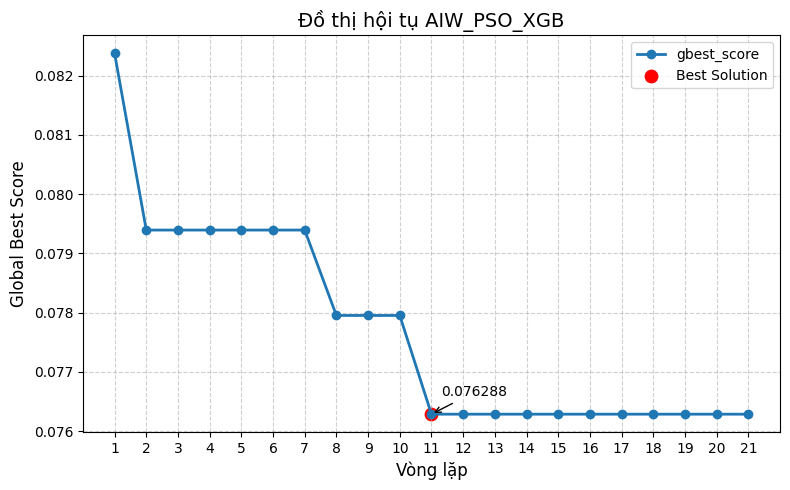

In [ ]:
import matplotlib.pyplot as plt

# Giá trị gbest_score theo từng vòng lặp
gbest_scores = [
  0.0823774434499067,
  0.07939539430409613,
  0.07939539430409613,
  0.07939539430409613,
  0.07939539430409613,
  0.07939539430409613,
  0.07939539430409613,
  0.07795402029362575,
  0.07795402029362575,
  0.07795402029362575,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048,
  0.0762877726848048
]

# Tạo danh sách số vòng lặp
iterations = range(1, len(gbest_scores) + 1)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))
plt.plot(
    iterations,
    gbest_scores,
    marker='o',
    linewidth=2,
    markersize=6,
    label='gbest_score'
)

# Đánh dấu điểm tốt nhất
best_iter = gbest_scores.index(min(gbest_scores)) + 1
best_score = min(gbest_scores)

plt.scatter(best_iter, best_score, s=80, color='red', label='Best Solution')
plt.annotate(
    f'{best_score:.6f}',
    xy=(best_iter, best_score),
    xytext=(best_iter + 0.3, best_score + 0.0003),
    arrowprops=dict(arrowstyle='->')
)

# Thiết lập đồ thị
plt.title("Đồ thị hội tụ AIW_PSO_XGB", fontsize=14)
plt.xlabel("Vòng lặp", fontsize=12)
plt.ylabel("Global Best Score", fontsize=12)
plt.xticks(iterations)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

In [11]:
# BO DU LIEU THỨ 2  20000 MẪU

from sklearn.datasets import fetch_openml

x, y = fetch_openml(
    "letter",
    version=1,
    return_X_y=True,
    as_frame=False
)

# OpenML returns string class labels; encode to integers for XGBoost.
encoder = LabelEncoder()
y = encoder.fit_transform(y)

In [12]:
print(x.shape)
print(y.shape)

(20000, 16)
(20000,)


In [ ]:
XGB(x, y)

Loss: 0.12207891714860239
Accuracy: 0.96255
Thoi gian thuc thi: 11.6803719997406


(np.float64(0.12207891714860239), np.float64(0.96255), 11.6803719997406)

In [ ]:
Grid_Search_XGB(x, y)

Bo sieu tham so tot nhat Grid Search: {'learning_rate': 0.2, 'max_depth': 6, 'n_estimators': 300, 'subsample': 0.85}
Loss: 0.11053475534966095
Accuracy: 0.9654
Thoi gian thuc thi: 1445.7871923446655


(np.float64(0.11053475534966095), np.float64(0.9654), 1445.7871923446655)

In [13]:
Random_search_XGB(x, y)

Best params Random Search: {'subsample': np.float64(0.8), 'n_estimators': 290, 'max_depth': 5, 'learning_rate': np.float64(0.16999999999999998)}
Loss: 0.1090380147683477
Accuracy: 0.9654999999999999
Thoi gian thuc thi: 2795.760390996933


(np.float64(0.1090380147683477),
 np.float64(0.9654999999999999),
 2795.760390996933)

In [ ]:
PSO_XGB(x, y)

Vong lap: 1 | gbest_score: 0.108283
Vong lap: 2 | gbest_score: 0.108283
Vong lap: 3 | gbest_score: 0.107935
Vong lap: 4 | gbest_score: 0.107173
Vong lap: 5 | gbest_score: 0.107173
Vong lap: 6 | gbest_score: 0.107173
Vong lap: 7 | gbest_score: 0.107173
Vong lap: 8 | gbest_score: 0.106906
Vong lap: 9 | gbest_score: 0.106906
Vong lap: 10 | gbest_score: 0.106148
Vong lap: 11 | gbest_score: 0.106148
Vong lap: 12 | gbest_score: 0.106148
Vong lap: 13 | gbest_score: 0.106148
Vong lap: 14 | gbest_score: 0.106094
Vong lap: 15 | gbest_score: 0.106094
Vong lap: 16 | gbest_score: 0.106094
Vong lap: 17 | gbest_score: 0.106094
Vong lap: 18 | gbest_score: 0.106036
Vong lap: 19 | gbest_score: 0.106036
Vong lap: 20 | gbest_score: 0.106036
Best params PSO-XGBoost: {'n_estimators': 500, 'max_depth': 5, 'learning_rate': 0.1628611556471292, 'subsample': 0.7798030036047452}
g_best_score: 0.10603647536074504
Accuracy: 0.9664000000000001
Thoi gian thuc thi: 28582.86411166191


(np.float64(0.10603647536074504),
 np.float64(0.9664000000000001),
 28582.86411166191,
 [np.float64(0.11099782137583851),
  np.float64(0.10828323530204802),
  np.float64(0.10828323530204802),
  np.float64(0.10793526615996704),
  np.float64(0.1071725802715328),
  np.float64(0.1071725802715328),
  np.float64(0.1071725802715328),
  np.float64(0.1071725802715328),
  np.float64(0.10690592096801424),
  np.float64(0.10690592096801424),
  np.float64(0.10614773120392569),
  np.float64(0.10614773120392569),
  np.float64(0.10614773120392569),
  np.float64(0.10614773120392569),
  np.float64(0.10609381719397015),
  np.float64(0.10609381719397015),
  np.float64(0.10609381719397015),
  np.float64(0.10609381719397015),
  np.float64(0.10603647536074504),
  np.float64(0.10603647536074504),
  np.float64(0.10603647536074504)])

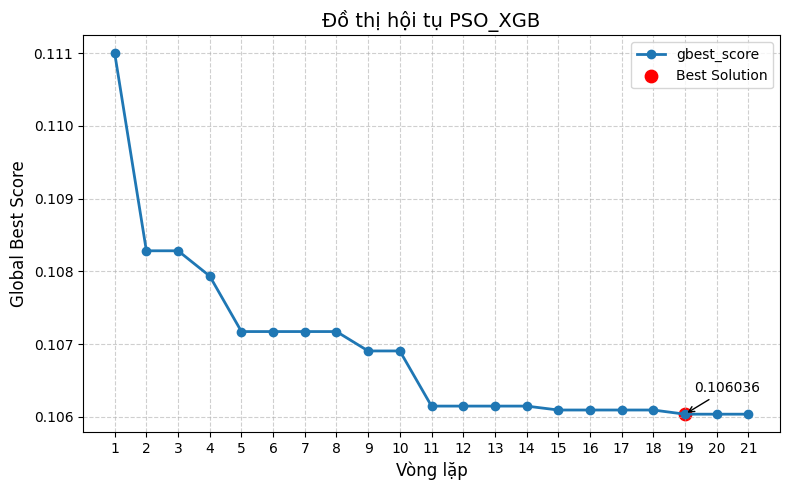

In [ ]:
import matplotlib.pyplot as plt

# Giá trị gbest_score theo từng vòng lặp
gbest_scores = [
  0.11099782137583851,
  0.10828323530204802,
  0.10828323530204802,
  0.10793526615996704,
  0.1071725802715328,
  0.1071725802715328,
  0.1071725802715328,
  0.1071725802715328,
  0.10690592096801424,
  0.10690592096801424,
  0.10614773120392569,
  0.10614773120392569,
  0.10614773120392569,
  0.10614773120392569,
  0.10609381719397015,
  0.10609381719397015,
  0.10609381719397015,
  0.10609381719397015,
  0.10603647536074504,
  0.10603647536074504,
  0.10603647536074504
]

# Tạo danh sách số vòng lặp
iterations = range(1, len(gbest_scores) + 1)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))
plt.plot(
    iterations,
    gbest_scores,
    marker='o',
    linewidth=2,
    markersize=6,
    label='gbest_score'
)

# Đánh dấu điểm tốt nhất
best_iter = gbest_scores.index(min(gbest_scores)) + 1
best_score = min(gbest_scores)

plt.scatter(best_iter, best_score, s=80, color='red', label='Best Solution')
plt.annotate(
    f'{best_score:.6f}',
    xy=(best_iter, best_score),
    xytext=(best_iter + 0.3, best_score + 0.0003),
    arrowprops=dict(arrowstyle='->')
)

# Thiết lập đồ thị
plt.title("Đồ thị hội tụ PSO_XGB", fontsize=14)
plt.xlabel("Vòng lặp", fontsize=12)
plt.ylabel("Global Best Score", fontsize=12)
plt.xticks(iterations)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
AIW_PSO_XGB(x, y)

Vong lap: 1 | gbest_score: 0.110998 | w_avg: 0.631 c1: 2.50 c2: 0.50 | mean_n_estimators: 272.1 mean_max_depth: 7.8 | reinit_triggered: False
Vong lap: 2 | gbest_score: 0.108726 | w_avg: 0.638 c1: 2.40 c2: 0.60 | mean_n_estimators: 289.7 mean_max_depth: 6.1 | reinit_triggered: False
Vong lap: 3 | gbest_score: 0.108311 | w_avg: 0.753 c1: 2.30 c2: 0.70 | mean_n_estimators: 316.9 mean_max_depth: 5.0 | reinit_triggered: False
Vong lap: 4 | gbest_score: 0.108173 | w_avg: 0.759 c1: 2.20 c2: 0.80 | mean_n_estimators: 345.3 mean_max_depth: 4.6 | reinit_triggered: False
Vong lap: 5 | gbest_score: 0.108173 | w_avg: 0.751 c1: 2.10 c2: 0.90 | mean_n_estimators: 321.5 mean_max_depth: 4.8 | reinit_triggered: False
Vong lap: 6 | gbest_score: 0.107466 | w_avg: 0.743 c1: 2.00 c2: 1.00 | mean_n_estimators: 309.2 mean_max_depth: 5.1 | reinit_triggered: False
Vong lap: 7 | gbest_score: 0.107466 | w_avg: 0.774 c1: 1.90 c2: 1.10 | mean_n_estimators: 323.2 mean_max_depth: 5.3 | reinit_triggered: False
Vong l

(np.float64(0.10710262831336462),
 np.float64(0.9663999999999999),
 26159.543912410736,
 [np.float64(0.11099782137583851),
  np.float64(0.11099782137583851),
  np.float64(0.10872576704719221),
  np.float64(0.10831071445960909),
  np.float64(0.10817266091681307),
  np.float64(0.10817266091681307),
  np.float64(0.10746566996902585),
  np.float64(0.10746566996902585),
  np.float64(0.1072403964167051),
  np.float64(0.1072403964167051),
  np.float64(0.1072403964167051),
  np.float64(0.1072403964167051),
  np.float64(0.10710262831336462),
  np.float64(0.10710262831336462),
  np.float64(0.10710262831336462),
  np.float64(0.10710262831336462),
  np.float64(0.10710262831336462),
  np.float64(0.10710262831336462),
  np.float64(0.10710262831336462),
  np.float64(0.10710262831336462),
  np.float64(0.10710262831336462)],
 [np.float64(0.6311954080270117),
  np.float64(0.6384468193554245),
  np.float64(0.7528703811051666),
  np.float64(0.7590368617180503),
  np.float64(0.7508671550026419),
  np.float

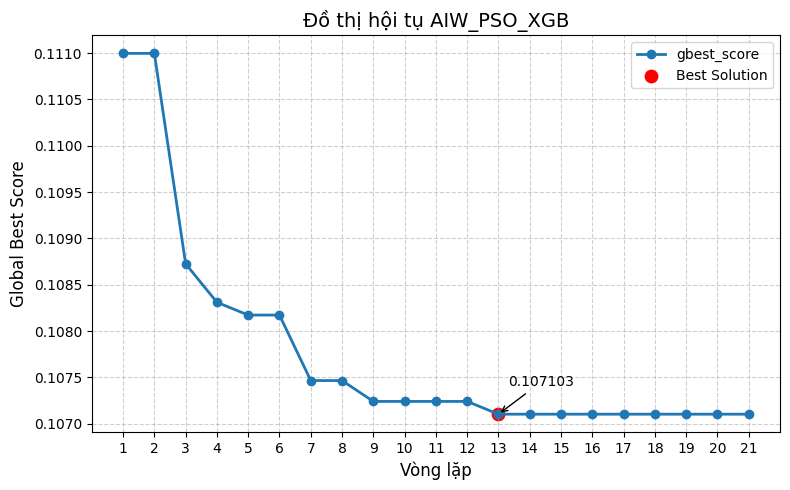

In [ ]:
import matplotlib.pyplot as plt

# Giá trị gbest_score theo từng vòng lặp
gbest_scores = [
  0.11099782137583851,
  0.11099782137583851,
  0.10872576704719221,
  0.10831071445960909,
  0.10817266091681307,
  0.10817266091681307,
  0.10746566996902585,
  0.10746566996902585,
  0.1072403964167051,
  0.1072403964167051,
  0.1072403964167051,
  0.1072403964167051,
  0.10710262831336462,
  0.10710262831336462,
  0.10710262831336462,
  0.10710262831336462,
  0.10710262831336462,
  0.10710262831336462,
  0.10710262831336462,
  0.10710262831336462,
  0.10710262831336462
]

# Tạo danh sách số vòng lặp
iterations = range(1, len(gbest_scores) + 1)

# Vẽ đồ thị
plt.figure(figsize=(8, 5))
plt.plot(
    iterations,
    gbest_scores,
    marker='o',
    linewidth=2,
    markersize=6,
    label='gbest_score'
)

# Đánh dấu điểm tốt nhất
best_iter = gbest_scores.index(min(gbest_scores)) + 1
best_score = min(gbest_scores)

plt.scatter(best_iter, best_score, s=80, color='red', label='Best Solution')
plt.annotate(
    f'{best_score:.6f}',
    xy=(best_iter, best_score),
    xytext=(best_iter + 0.3, best_score + 0.0003),
    arrowprops=dict(arrowstyle='->')
)

# Thiết lập đồ thị
plt.title("Đồ thị hội tụ AIW_PSO_XGB", fontsize=14)
plt.xlabel("Vòng lặp", fontsize=12)
plt.ylabel("Global Best Score", fontsize=12)
plt.xticks(iterations)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()